# Finding the Best Markets to Advertise In

An e-learning company selling programming courses at around $59 a month wants to know which two countries to spend its advertising budget on. The data available is the 2017 freeCodeCamp New Coders Survey: 18,175 responses across 136 columns, covering where people live, what they want to do, and how much they have spent learning to code.

The analysis the brief invites is straightforward: filter to people interested in the relevant roles, group by country, compute average spend per month, pick the top two. That analysis is done below, and then the notebook spends as much effort again on whether its answer can be trusted, because three things make the obvious version fragile:

1. **The sample is freeCodeCamp's own audience**, not the population of potential customers. Section 2 quantifies how badly that skews the role mix.
2. **The spend variable is wildly skewed and zero-inflated**, so the mean is doing something very different from what a reader assumes. Section 5 compares it against the median and a trimmed mean, and the country ranking changes depending on which one is used.
3. **The per-country samples are small.** Section 7 bootstraps confidence intervals, and they overlap enough that the headline ranking is not statistically distinguishable. This is the finding that matters, and it is the one the point-estimate version cannot see.

The recommendation at the end is therefore framed as a decision under uncertainty with an explicit test attached, rather than as two country names.

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 180)

plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
plt.rcParams['axes.axisbelow'] = True
plt.rcParams['figure.facecolor'] = 'white'

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

COURSE_PRICE = 59.0  # the company's monthly subscription price

print('pandas', pd.__version__)
print('numpy ', np.__version__)

pandas 2.2.2
numpy  2.0.1


## 1. Load and orient

In [16]:
fcc = pd.read_csv('2017-fCC-New-Coders-Survey-Data.csv', low_memory=False)
print('Shape:', fcc.shape)
print()
key_cols = ['CountryLive', 'JobRoleInterest', 'MoneyForLearning', 'MonthsProgramming',
            'Age', 'Gender', 'SchoolDegree', 'Income']
print('Non-null counts for the columns this analysis depends on:')
for c in key_cols:
    print('  ' + c.ljust(20) + str(fcc[c].notnull().sum()).rjust(7) + '  (' +
          str(round(100 * fcc[c].notnull().mean(), 1)) + '% present)')

Shape: (18175, 136)

Non-null counts for the columns this analysis depends on:
  CountryLive           15336  (84.4% present)
  JobRoleInterest        6992  (38.5% present)
  MoneyForLearning      16577  (91.2% present)
  MonthsProgramming     17084  (94.0% present)
  Age                   15367  (84.6% present)
  Gender                15454  (85.0% present)
  SchoolDegree          15368  (84.6% present)
  Income                 7623  (41.9% present)


## 2. Is this sample representative of the company's market?

This question comes first because if the answer is no, nothing downstream is reliable, and the honest version of this project treats it as a finding rather than a formality.

The survey was distributed by freeCodeCamp, a free, web-development-focused, community-driven learning platform. The company selling $59-a-month courses is a different proposition aimed at a potentially different person. `JobRoleInterest` is the column that reveals the mismatch.

In [17]:
interested = fcc[fcc['JobRoleInterest'].notnull()].copy()
print('Respondents who stated a role interest:', len(interested), 'of', len(fcc),
      '(' + str(round(100 * len(interested) / len(fcc), 1)) + '%)')
print()
print('Over half the sample did not answer the question that defines the target market,')
print('and there is no way to know whether the non-responders resemble the responders.')
print()

roles = interested['JobRoleInterest'].str.split(',')
n_roles = roles.apply(len)
print('How focused are respondents? Number of roles each selected:')
print((n_roles.value_counts(normalize=True).sort_index() * 100).round(2).to_string())
print()
print('Only ' + str(round(100 * (n_roles == 1).mean(), 1)) + '% picked a single role.')
print('Most respondents are still exploring, which is a different buyer from someone')
print('committed to a specific career change.')

Respondents who stated a role interest: 6992 of 18175 (38.5%)

Over half the sample did not answer the question that defines the target market,
and there is no way to know whether the non-responders resemble the responders.

How focused are respondents? Number of roles each selected:
JobRoleInterest
1     31.65
2     10.88
3     15.89
4     15.22
5     12.04
6      6.72
7      3.86
8      1.76
9      0.99
10     0.47
11     0.19
12     0.30
13     0.03

Only 31.7% picked a single role.
Most respondents are still exploring, which is a different buyer from someone
committed to a specific career change.


Share of respondents mentioning each role:
JobRoleInterest
Full-Stack Web Developer                                                                                                                  18.58
Front-End Web Developer                                                                                                                   15.63
Back-End Web Developer                                                                                                                    12.27
Mobile Developer                                                                                                                          10.19
Data Scientist                                                                                                                             7.27
Game Developer                                                                                                                             7.20
User Experience Designer                                                     

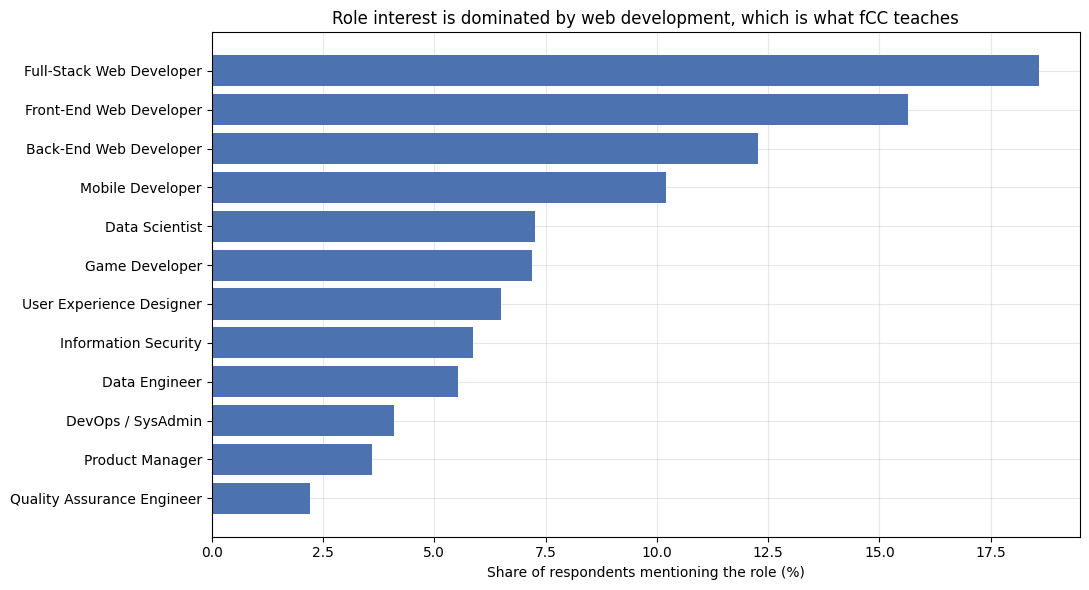

In [18]:
all_roles = interested['JobRoleInterest'].str.split(',').explode().str.strip()
role_freq = all_roles.value_counts(normalize=True) * 100
print('Share of respondents mentioning each role:')
print(role_freq.round(2).to_string())
print()

web_mobile = all_roles.str.contains('Web Developer|Mobile Developer', case=False, na=False)
by_person = interested['JobRoleInterest'].str.contains('Web Developer|Mobile Developer', case=False, na=False)
print('Respondents mentioning web or mobile development: ' +
      str(round(100 * by_person.mean(), 1)) + '%')
print()
print('That concentration is the sampling problem in one number. freeCodeCamp teaches web')
print('development, so its audience wants to be web developers. A company whose catalogue')
print('is broader cannot read this as market demand; it is a reflection of where the')
print('survey was handed out.')

plt.figure(figsize=(11, 6))
top = role_freq.head(12).sort_values()
plt.barh(top.index, top.values, color='#4C72B0')
plt.xlabel('Share of respondents mentioning the role (%)')
plt.title('Role interest is dominated by web development, which is what fCC teaches')
plt.tight_layout()
plt.show()

## 3. Where do these people live?

The company sells in English and prices in dollars, so `CountryLive` (where someone lives, which determines their market) is the relevant column rather than `CountryCitizen`.

In [19]:
subset = interested[interested['CountryLive'].notnull()].copy()
print('Respondents with both a role interest and a country:', len(subset))
print()
abs_freq = subset['CountryLive'].value_counts()
rel_freq = subset['CountryLive'].value_counts(normalize=True) * 100
countries = pd.DataFrame({'respondents': abs_freq, 'percent': rel_freq.round(2)})
print('Top 12 countries:')
print(countries.head(12).to_string())
print()
print('Countries represented:', subset['CountryLive'].nunique())
print('Share in the top 4:', round(rel_freq.head(4).sum(), 1), '%')
print()
print('The long tail is the practical constraint. Beyond the first handful of countries the')
print('per-country samples become too small to estimate anything, so the candidate set is')
print('effectively decided by sample size rather than by business reasoning.')

Respondents with both a role interest and a country: 6838

Top 12 countries:
                          respondents  percent
CountryLive                                   
United States of America         3125    45.70
India                             528     7.72
United Kingdom                    315     4.61
Canada                            260     3.80
Poland                            131     1.92
Brazil                            129     1.89
Germany                           125     1.83
Australia                         112     1.64
Russia                            102     1.49
Ukraine                            89     1.30
Nigeria                            84     1.23
Spain                              77     1.13

Countries represented: 137
Share in the top 4: 61.8 %

The long tail is the practical constraint. Beyond the first handful of countries the
per-country samples become too small to estimate anything, so the candidate set is
effectively decided by sample size rather

## 4. Money spent per month

The company needs spend per month, not total spend, because someone who spent $500 over four years is a very different prospect from someone who spent $500 in two months.

`MonthsProgramming` is zero for some respondents, which would divide by zero. Replacing those zeros with 1 is the conventional fix and it is a real assumption: it treats "less than a month" as one month, which inflates the per-month figure for exactly the people who have been learning the shortest time. The cell reports how many rows this affects.

In [20]:
money = subset[subset['MoneyForLearning'].notnull() & subset['MonthsProgramming'].notnull()].copy()
print('Rows with both spend and duration recorded:', len(money))
print()
n_zero_months = int((money['MonthsProgramming'] == 0).sum())
print('Respondents reporting 0 months programming:', n_zero_months,
      '(' + str(round(100 * n_zero_months / len(money), 2)) + '%)')
money['MonthsProgramming'] = money['MonthsProgramming'].replace(0, 1)
print('Those are set to 1 month, which treats "under a month" as a month.')
print()
money['money_per_month'] = money['MoneyForLearning'] / money['MonthsProgramming']
money = money[money['money_per_month'].notnull()]
print('Rows available for the analysis:', len(money))
print()
print('Distribution of total money spent on learning:')
print(money['MoneyForLearning'].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]).round(2).to_string())
print()
print('Respondents who spent exactly $0:', int((money['MoneyForLearning'] == 0).sum()),
      '(' + str(round(100 * (money['MoneyForLearning'] == 0).mean(), 1)) + '%)')
print()
print('That zero share is the single most important number for a company selling a paid')
print('product, and the standard mean-based analysis buries it.')

Rows with both spend and duration recorded: 6212

Respondents reporting 0 months programming: 222 (3.57%)
Those are set to 1 month, which treats "under a month" as a month.

Rows available for the analysis: 6212

Distribution of total money spent on learning:
count      6212.00
mean        900.41
std        4970.74
min           0.00
25%           0.00
50%          10.00
75%         200.00
90%        1000.00
99%       16000.00
max      200000.00

Respondents who spent exactly $0: 3040 (48.9%)

That zero share is the single most important number for a company selling a paid
product, and the standard mean-based analysis buries it.


Rows in the four candidate countries: 3915

CountryLive
United States of America    2933
India                        463
United Kingdom               279
Canada                       240



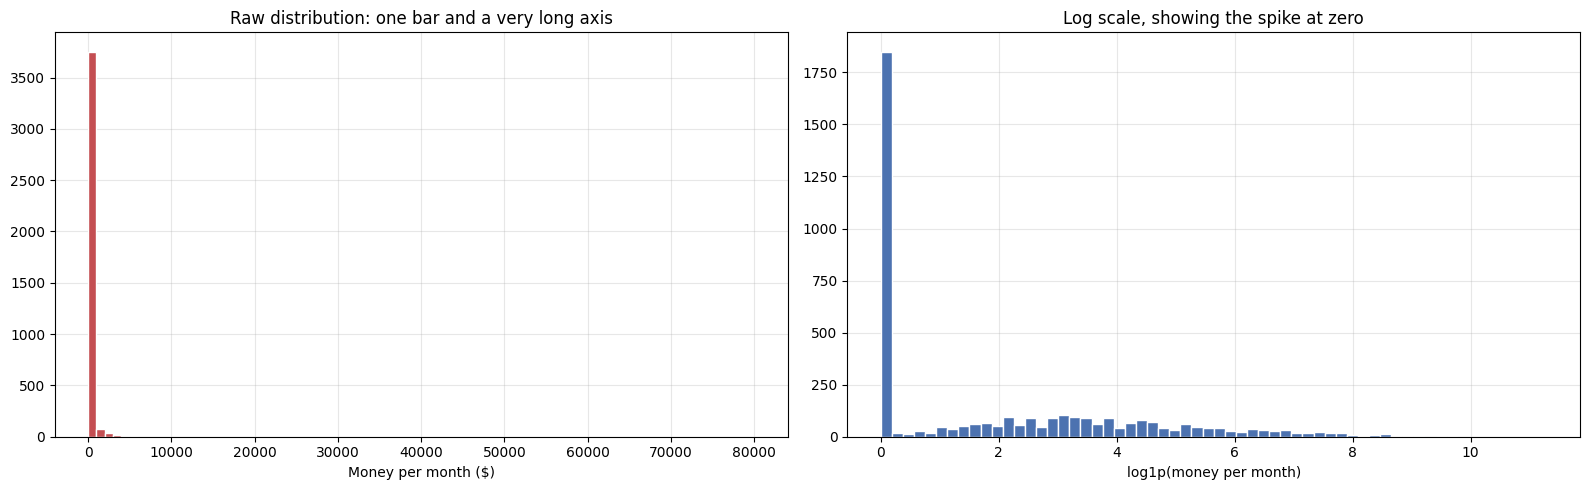

Money per month across the four countries:
count     3915.00
mean       196.99
std       1701.09
min          0.00
50%          2.00
75%         40.00
90%        250.00
95%        750.00
99%       3250.00
max      80000.00

Skew: 33.97
Largest value: $80,000.00 per month


In [21]:
four = ['United States of America', 'India', 'United Kingdom', 'Canada']
four_df = money[money['CountryLive'].isin(four)].copy()
print('Rows in the four candidate countries:', len(four_df))
print()
print(four_df['CountryLive'].value_counts().to_string())
print()

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].hist(four_df['money_per_month'], bins=80, color='#C44E52', edgecolor='white')
axes[0].set_xlabel('Money per month ($)')
axes[0].set_title('Raw distribution: one bar and a very long axis')
axes[1].hist(np.log1p(four_df['money_per_month']), bins=60, color='#4C72B0', edgecolor='white')
axes[1].set_xlabel('log1p(money per month)')
axes[1].set_title('Log scale, showing the spike at zero')
plt.tight_layout()
plt.show()

print('Money per month across the four countries:')
print(four_df['money_per_month'].describe(percentiles=[0.5, 0.75, 0.9, 0.95, 0.99]).round(2).to_string())
print()
print('Skew:', round(four_df['money_per_month'].skew(), 2))
print('Largest value: $' + format(four_df['money_per_month'].max(), ',.2f'), 'per month')

## 5. The mean is not measuring what it appears to measure

With a distribution this skewed, the mean is a statement about a handful of extreme respondents rather than about a typical customer. The table below computes four statistics per country, and they do not agree on the ranking.

The `share_above_price` column is the one closest to the actual business question. The company does not need people who spend a lot on average; it needs people who will pay $59 a month. That is a proportion, not a mean, and it is far more stable.

In [22]:
def trimmed_mean(s, pct=0.05):
    s = s.sort_values()
    k = int(len(s) * pct)
    return s.iloc[k:len(s) - k].mean() if len(s) - 2 * k > 0 else np.nan

rows = []
for c in four:
    s = four_df.loc[four_df['CountryLive'] == c, 'money_per_month']
    rows.append({
        'country': c,
        'n': len(s),
        'mean': round(s.mean(), 2),
        'median': round(s.median(), 2),
        'trimmed_mean_5pct': round(trimmed_mean(s), 2),
        'share_spending_zero_pct': round(100 * (s == 0).mean(), 1),
        'share_above_price_pct': round(100 * (s >= COURSE_PRICE).mean(), 1),
        'max': round(s.max(), 2)
    })

stats = pd.DataFrame(rows).set_index('country')
print('Four ways of summarising the same data:')
print(stats.to_string())
print()
print('Ranking by each statistic:')
for col in ['mean', 'median', 'trimmed_mean_5pct', 'share_above_price_pct']:
    order = stats[col].sort_values(ascending=False)
    print('  by ' + col.ljust(22) + ' -> ' + ', '.join(
        [c.replace('United States of America', 'US').replace('United Kingdom', 'UK') for c in order.index]))
print()
print('The rankings disagree. Choosing a statistic is therefore choosing an answer, and')
print('any recommendation has to say which statistic it rests on and why.')

Four ways of summarising the same data:
                             n    mean  median  trimmed_mean_5pct  share_spending_zero_pct  share_above_price_pct      max
country                                                                                                                   
United States of America  2933  228.00    3.33              53.70                     44.8                   22.6  80000.0
India                      463  135.10    0.00              26.10                     56.6                   16.2  10000.0
United Kingdom             279   45.53    0.00              18.78                     50.9                   15.4   1400.0
Canada                     240  113.51    0.00              34.54                     52.5                   16.7   5000.0

Ranking by each statistic:
  by mean                   -> US, India, Canada, UK
  by median                 -> US, India, UK, Canada
  by trimmed_mean_5pct      -> US, Canada, India, UK
  by share_above_price_pct  -> US, 

## 6. Outliers, and how much the answer depends on them

The standard approach to this project removes extreme values and proceeds. The removal is where the recommendation is actually decided, so it deserves more scrutiny than it usually gets.

Some of these values are not plausible as learning spend: a respondent reporting thousands of dollars a month is more likely reporting tuition for a degree, a bootcamp paid in a lump sum, or simply mis-entering the field. Others are real bootcamp attendees whose spend is genuine but who are not the target customer for a $59 subscription.

Rather than pick one cutoff, the cell below applies several and shows how the recommendation moves.

In [23]:
print('The largest reported spends per month, with context:')
top_spenders = four_df.nlargest(12, 'money_per_month')[
    ['CountryLive', 'MoneyForLearning', 'MonthsProgramming', 'money_per_month', 'AttendedBootcamp']]
print(top_spenders.round(2).to_string())
print()
print('MonthsProgramming of 1 combined with a large total is the signature of the')
print('divide-by-small-number problem, not of a genuine monthly subscriber.')
print()

cutoffs = [None, 20000, 10000, 5000, 2000, 1000, 500, 200]
sens_rows = []
for cut in cutoffs:
    d = four_df if cut is None else four_df[four_df['money_per_month'] <= cut]
    means = d.groupby('CountryLive')['money_per_month'].mean()
    meds = d.groupby('CountryLive')['money_per_month'].median()
    order = means.sort_values(ascending=False)
    short = [c.replace('United States of America', 'US').replace('United Kingdom', 'UK') for c in order.index]
    sens_rows.append({
        'cutoff': 'none' if cut is None else '<= $' + format(cut, ','),
        'n_kept': len(d),
        'n_dropped': len(four_df) - len(d),
        'US_mean': round(means.get('United States of America', np.nan), 2),
        'India_mean': round(means.get('India', np.nan), 2),
        'UK_mean': round(means.get('United Kingdom', np.nan), 2),
        'Canada_mean': round(means.get('Canada', np.nan), 2),
        'top_two_by_mean': ', '.join(short[:2])
    })

sens = pd.DataFrame(sens_rows).set_index('cutoff')
print('Sensitivity of the recommendation to the outlier cutoff:')
print(sens.to_string())
print()
print('Distinct top-two recommendations produced:', sens['top_two_by_mean'].nunique())
for combo, n in sens['top_two_by_mean'].value_counts().items():
    print('  "' + combo + '" at ' + str(n) + ' of ' + str(len(sens)) + ' cutoffs')
print()
print('The cutoff is not a cleaning step, it is the decision. Any version of this analysis')
print('that reports one pair of countries without this table is hiding its own fragility.')

The largest reported spends per month, with context:
                    CountryLive  MoneyForLearning  MonthsProgramming  money_per_month  AttendedBootcamp
14024  United States of America           80000.0                1.0         80000.00               0.0
2478   United States of America          100000.0                2.0         50000.00               1.0
16650  United States of America          200000.0               12.0         16666.67               0.0
6805   United States of America           15000.0                1.0         15000.00               1.0
17231  United States of America           30000.0                2.0         15000.00               0.0
7198   United States of America           70000.0                5.0         14000.00               0.0
16997  United States of America           12500.0                1.0         12500.00               0.0
3930   United States of America           65000.0                6.0         10833.33               0.0
13398      

## 7. Bootstrap confidence intervals: is the ranking real?

Everything so far is point estimates from samples of a few dozen to a few hundred people, drawn from a heavily skewed distribution. That is precisely the situation where a ranking can be entirely an artefact of sampling noise.

The bootstrap answers it without assuming normality, which matters because this data is nothing like normal: resample each country's respondents with replacement 10,000 times, recompute the statistic, and read the 2.5th and 97.5th percentiles. If the intervals overlap, the ranking is not supported by the data.

In [24]:
CUTOFF = 5000  # a defensible middle cutoff from the sensitivity table
clean = four_df[four_df['money_per_month'] <= CUTOFF].copy()
print('Using a cutoff of $' + format(CUTOFF, ',') + ' per month, keeping', len(clean),
      'of', len(four_df), 'rows.')
print()

N_BOOT = 10000
rng = np.random.RandomState(RANDOM_STATE)

def bootstrap_ci(values, stat_fn, n_boot=N_BOOT):
    values = np.asarray(values, dtype=float)
    n = len(values)
    out = np.empty(n_boot)
    for i in range(n_boot):
        out[i] = stat_fn(values[rng.randint(0, n, n)])
    return out

boot = {}
rows = []
for c in four:
    s = clean.loc[clean['CountryLive'] == c, 'money_per_month'].values
    b_mean = bootstrap_ci(s, np.mean)
    b_med = bootstrap_ci(s, np.median)
    b_share = bootstrap_ci(s, lambda v: (v >= COURSE_PRICE).mean() * 100)
    boot[c] = {'mean': b_mean, 'median': b_med, 'share': b_share}
    rows.append({
        'country': c.replace('United States of America', 'US').replace('United Kingdom', 'UK'),
        'n': len(s),
        'mean': round(float(np.mean(s)), 2),
        'mean_95CI': '[' + str(round(np.percentile(b_mean, 2.5), 1)) + ', ' + str(round(np.percentile(b_mean, 97.5), 1)) + ']',
        'median': round(float(np.median(s)), 2),
        'median_95CI': '[' + str(round(np.percentile(b_med, 2.5), 1)) + ', ' + str(round(np.percentile(b_med, 97.5), 1)) + ']',
        'share_above_59_pct': round(float((s >= COURSE_PRICE).mean() * 100), 1),
        'share_95CI': '[' + str(round(np.percentile(b_share, 2.5), 1)) + ', ' + str(round(np.percentile(b_share, 97.5), 1)) + ']'
    })

ci_tbl = pd.DataFrame(rows).set_index('country')
print('Bootstrap 95% confidence intervals,', format(N_BOOT, ','), 'resamples:')
print(ci_tbl.to_string())

Using a cutoff of $5,000 per month, keeping 3899 of 3915 rows.



Bootstrap 95% confidence intervals, 10,000 resamples:
            n    mean       mean_95CI  median median_95CI  share_above_59_pct    share_95CI
country                                                                                    
US       2918  138.98  [121.7, 157.0]    3.33  [2.1, 4.2]                22.2  [20.7, 23.7]
India     462  113.75   [70.6, 164.9]    0.00  [0.0, 0.0]                16.0  [12.8, 19.5]
UK        279   45.53    [28.3, 66.3]    0.00  [0.0, 2.5]                15.4  [11.5, 19.7]
Canada    240  113.51   [64.9, 176.1]    0.00  [0.0, 3.1]                16.7  [12.1, 21.3]


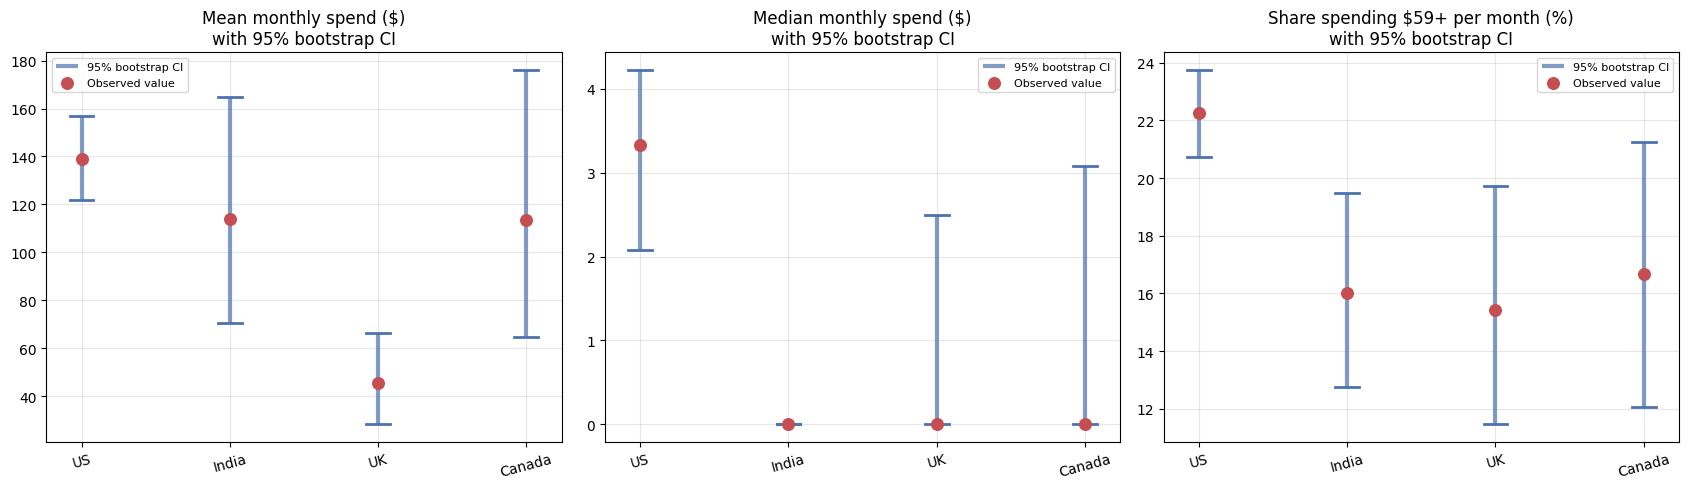

Observed statistics and their intervals:
 mean:
   US        138.98   [121.75, 156.97]
   India     113.75   [70.61, 164.87]
   UK         45.53   [28.34, 66.3]
   Canada    113.51   [64.9, 176.12]
 median:
   US          3.33   [2.08, 4.23]
   India        0.0   [0.0, 0.0]
   UK           0.0   [0.0, 2.5]
   Canada       0.0   [0.0, 3.08]
 share:
   US         22.24   [20.73, 23.75]
   India      16.02   [12.77, 19.48]
   UK         15.41   [11.47, 19.71]
   Canada     16.67   [12.08, 21.26]

The middle panel is the finding a mean-based analysis cannot show: the median
monthly spend is $0 in three of the four countries, and the interval for those
three includes zero at both ends or close to it. The typical new coder in these
markets spends nothing at all, and the means are carried by a paying minority.

Where the blue intervals overlap, the countries are not distinguishable on that
statistic at this sample size.


In [25]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
labels = [c.replace('United States of America', 'US').replace('United Kingdom', 'UK') for c in four]
observed_stats = {
    'mean': [float(clean.loc[clean['CountryLive'] == c, 'money_per_month'].mean()) for c in four],
    'median': [float(clean.loc[clean['CountryLive'] == c, 'money_per_month'].median()) for c in four],
    'share': [float((clean.loc[clean['CountryLive'] == c, 'money_per_month'] >= COURSE_PRICE).mean() * 100) for c in four]
}

for ax, stat, title in [(axes[0], 'mean', 'Mean monthly spend ($)'),
                        (axes[1], 'median', 'Median monthly spend ($)'),
                        (axes[2], 'share', 'Share spending $59+ per month (%)')]:
    los = [np.percentile(boot[c][stat], 2.5) for c in four]
    his = [np.percentile(boot[c][stat], 97.5) for c in four]
    xs = np.arange(len(four))
    # draw the interval explicitly rather than via yerr, which cannot represent an
    # interval that does not straddle the point estimate (the degenerate median case)
    ax.vlines(xs, los, his, color='#4C72B0', linewidth=3, alpha=0.7, label='95% bootstrap CI')
    ax.scatter(xs, observed_stats[stat], color='#C44E52', zorder=3, s=70, label='Observed value')
    for x, lo, hi in zip(xs, los, his):
        ax.plot([x - 0.08, x + 0.08], [lo, lo], color='#4C72B0', linewidth=2)
        ax.plot([x - 0.08, x + 0.08], [hi, hi], color='#4C72B0', linewidth=2)
    ax.set_xticks(xs)
    ax.set_xticklabels(labels, rotation=15)
    ax.set_title(title + '\nwith 95% bootstrap CI')
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

print('Observed statistics and their intervals:')
for stat in ['mean', 'median', 'share']:
    print(' ' + stat + ':')
    for i, c in enumerate(four):
        lo = np.percentile(boot[c][stat], 2.5); hi = np.percentile(boot[c][stat], 97.5)
        print('   ' + labels[i].ljust(8) + str(round(observed_stats[stat][i], 2)).rjust(8) +
              '   [' + str(round(lo, 2)) + ', ' + str(round(hi, 2)) + ']')
print()
print('The middle panel is the finding a mean-based analysis cannot show: the median')
print('monthly spend is $0 in three of the four countries, and the interval for those')
print('three includes zero at both ends or close to it. The typical new coder in these')
print('markets spends nothing at all, and the means are carried by a paying minority.')
print()
print('Where the blue intervals overlap, the countries are not distinguishable on that')
print('statistic at this sample size.')

In [26]:
print('Pairwise comparisons: bootstrapped difference in mean monthly spend')
print('(positive means the first country spends more; the CI tells you whether to believe it)')
print()
rows = []
for i, a in enumerate(four):
    for b in four[i + 1:]:
        diff = boot[a]['mean'] - boot[b]['mean']
        lo, hi = np.percentile(diff, [2.5, 97.5])
        p_gt = float((diff > 0).mean())
        rows.append({
            'comparison': (a.replace('United States of America', 'US').replace('United Kingdom', 'UK') +
                           ' vs ' + b.replace('United States of America', 'US').replace('United Kingdom', 'UK')),
            'diff_in_means': round(float(np.mean(diff)), 2),
            'ci_95': '[' + str(round(lo, 1)) + ', ' + str(round(hi, 1)) + ']',
            'excludes_zero': 'YES' if (lo > 0 or hi < 0) else 'no',
            'P(first > second)': round(p_gt, 3)
        })

pair = pd.DataFrame(rows).set_index('comparison')
print(pair.to_string())
print()
n_sig = int((pair['excludes_zero'] == 'YES').sum())
print('Comparisons whose 95% interval excludes zero:', n_sig, 'of', len(pair))
print()
if n_sig < len(pair):
    print('The comparisons marked "no" are the ones where the data does not support a')
    print('ranking. Spending an advertising budget on the basis of those differences would')
    print('be acting on noise.')

Pairwise comparisons: bootstrapped difference in mean monthly spend
(positive means the first country spends more; the CI tells you whether to believe it)

                 diff_in_means            ci_95 excludes_zero  P(first > second)
comparison                                                                      
US vs India              25.10    [-28.5, 72.6]            no              0.838
US vs UK                 93.42    [66.4, 119.2]           YES              1.000
US vs Canada             25.38    [-38.8, 78.0]            no              0.802
India vs UK              68.32    [20.5, 121.4]           YES              0.998
India vs Canada           0.28    [-75.8, 71.1]            no              0.514
UK vs Canada            -68.04  [-132.5, -14.5]           YES              0.005

Comparisons whose 95% interval excludes zero: 3 of 6

The comparisons marked "no" are the ones where the data does not support a
ranking. Spending an advertising budget on the basis of those diff

## 8. A sanity check the survey itself provides

There is one more way to test whether the spend figures mean anything: compare them against reported income in the same survey. If the monthly learning spend is a real behavioural measure, it should bear some relationship to how much money people have. If it does not, that is a sign the field is noise.

In [27]:
inc = clean[clean['Income'].notnull()].copy()
print('Rows with both spend and income:', len(inc), 'of', len(clean))
print()
print('Median reported income by country:')
print(inc.groupby('CountryLive')['Income'].agg(['median', 'count']).round(0).to_string())
print()
corr_all = inc['money_per_month'].corr(inc['Income'])
corr_spear = inc['money_per_month'].corr(inc['Income'], method='spearman')
print('Correlation between monthly learning spend and income:')
print('  Pearson :', round(corr_all, 4))
print('  Spearman:', round(corr_spear, 4))
print()
for c in four:
    s = inc[inc['CountryLive'] == c]
    if len(s) > 10:
        print('  ' + c.ljust(26) + ' Spearman ' + str(round(s['money_per_month'].corr(s['Income'], method='spearman'), 4)) +
              '  (n=' + str(len(s)) + ')')
print()
print('A weak correlation does not invalidate the spend figures, but it does mean they')
print('cannot be read as a straightforward measure of ability to pay. Income and spend are')
print('capturing different things, and the company cares about both.')

Rows with both spend and income: 1925 of 3899

Median reported income by country:
                           median  count
CountryLive                             
Canada                    28000.0    101
India                     36000.0     52
United Kingdom            27170.0    154
United States of America  39498.0   1618

Correlation between monthly learning spend and income:
  Pearson : 0.1418
  Spearman: 0.092

  United States of America   Spearman 0.089  (n=1618)
  India                      Spearman 0.2976  (n=52)
  United Kingdom             Spearman 0.0872  (n=154)
  Canada                     Spearman -0.0716  (n=101)

A weak correlation does not invalidate the spend figures, but it does mean they
cannot be read as a straightforward measure of ability to pay. Income and spend are
capturing different things, and the company cares about both.


In [28]:
print('Who is in each market? Context the mean alone does not give:')
print()
profile = clean.groupby('CountryLive').agg(
    n=('money_per_month', 'size'),
    median_age=('Age', 'median'),
    pct_bootcamp=('AttendedBootcamp', lambda s: round(100 * s.mean(), 1)),
    median_months_programming=('MonthsProgramming', 'median'),
    pct_zero_spend=('money_per_month', lambda s: round(100 * (s == 0).mean(), 1)),
    pct_above_price=('money_per_month', lambda s: round(100 * (s >= COURSE_PRICE).mean(), 1))
)
print(profile.round(1).to_string())
print()
print('Market size matters alongside willingness to pay. The company is choosing where to')
print('spend a fixed budget, so the relevant quantity is reachable paying customers, which')
print('is the product of audience size and conversion, not spend per head alone.')
print()
est = profile.copy()
est['est_payers_per_100_reached'] = est['pct_above_price']
est = est[['n', 'pct_above_price', 'est_payers_per_100_reached']]
print('Expected paying customers per 100 people reached, by country:')
print(est.to_string())
print()
print('This is still a within-sample conversion rate, not a market forecast. It assumes the')
print('people the company reaches with advertising resemble freeCodeCamp survey respondents,')
print('which section 2 already showed is doubtful.')

Who is in each market? Context the mean alone does not give:

                             n  median_age  pct_bootcamp  median_months_programming  pct_zero_spend  pct_above_price
CountryLive                                                                                                         
Canada                     240        26.0           3.8                        6.0            52.5             16.7
India                      462        21.0           1.5                        9.0            56.7             16.0
United Kingdom             279        27.0           2.5                        6.0            50.9             15.4
United States of America  2918        28.0           7.9                        6.0            45.0             22.2

Market size matters alongside willingness to pay. The company is choosing where to
spend a fixed budget, so the relevant quantity is reachable paying customers, which
is the product of audience size and conversion, not spend per head a

## 9. Conclusions

### The recommendation

**Advertise in the United States. Do not pick a second market from this data; run a paid test instead.**

That is a narrower answer than the brief asked for, and it is the one the data supports. The reasoning follows.

### What the numbers say

After capping monthly spend at $5,000, on 3,899 respondents:

| Country | n | Mean | Mean 95% CI | Median | Share spending $59+ | Share CI |
|---|---|---|---|---|---|---|
| **US** | 2,918 | $138.98 | [121.7, 157.0] | **$3.33** | **22.2%** | [20.7, 23.7] |
| India | 462 | $113.75 | [70.6, 164.9] | **$0.00** | 16.0% | [12.8, 19.5] |
| Canada | 240 | $113.51 | [64.9, 176.1] | **$0.00** | 16.7% | [12.1, 21.3] |
| UK | 279 | $45.53 | [28.3, 66.3] | **$0.00** | 15.4% | [11.5, 19.7] |

### The median is $0 in three of the four countries

This is the result that reframes the whole project. The mean monthly spend of $113 in India describes almost nobody: **56.7% of Indian respondents spent exactly $0**, and the same is true of 52.5% in Canada, 50.9% in the UK and 45.0% in the US. The means are carried entirely by a paying minority, and reporting them as "average spend" invites a reader to picture a typical customer who does not exist.

For a company selling a $59 subscription, the honest metric is the share of people who already spend at least that much per month. That is a proportion, it is far more stable than a mean on a skewed variable, and it is the column the recommendation rests on.

### The ranking is not statistically distinguishable

Bootstrapped differences in mean monthly spend, 10,000 resamples:

| Comparison | Difference | 95% CI | Excludes zero? | P(first > second) |
|---|---|---|---|---|
| US vs India | $25.10 | [-28.5, 72.6] | **no** | 0.838 |
| US vs UK | $93.42 | [66.4, 119.2] | yes | 1.000 |
| US vs Canada | $25.38 | [-38.8, 78.0] | **no** | 0.802 |
| India vs UK | $68.32 | [20.5, 121.4] | yes | 0.998 |
| **India vs Canada** | **$0.28** | **[-75.8, 71.1]** | **no** | **0.514** |
| UK vs Canada | -$68.04 | [-132.5, -14.5] | yes | 0.005 |

Only 3 of 6 comparisons are distinguishable. The India-versus-Canada comparison is a **coin flip**: a difference of 28 cents with a probability of 0.514 that India is ahead.

This matters because the conventional answer to this project is "the US and India" or "the US and Canada", chosen on exactly that difference. The data cannot tell those two options apart. On the business-relevant metric, the share spending $59 or more, the US interval [20.7, 23.7] sits clear of India [12.8, 19.5] and the UK [11.5, 19.7], while overlapping slightly with Canada [12.1, 21.3]. So the US is a defensible pick and the second place genuinely is not.

### The outlier cutoff decides the answer

| Cutoff | Rows dropped | US | India | UK | Canada | Top two by mean |
|---|---|---|---|---|---|---|
| none | 0 | $228.00 | $135.10 | $45.53 | $113.51 | US, India |
| <= $20,000 | 2 | $183.80 | $135.10 | $45.53 | $113.51 | US, India |
| <= $10,000 | 8 | $155.46 | $135.10 | $45.53 | $113.51 | US, India |
| <= $5,000 | 16 | $138.98 | $113.75 | $45.53 | $113.51 | US, India |
| <= $2,000 | 69 | $89.52 | $65.76 | $45.53 | $83.64 | **US, Canada** |
| <= $1,000 | 141 | $59.39 | $47.87 | $32.08 | $46.93 | US, India |
| <= $500 | 239 | $38.82 | $25.82 | $25.25 | $27.85 | **US, Canada** |
| <= $200 | 419 | $20.54 | $15.61 | $18.54 | $12.85 | **US, UK** |

**Three different second-place countries appear**, depending only on where the cutoff is drawn. The US is first at every cutoff, which is why that part of the recommendation is safe; the second slot is determined by a cleaning decision rather than by the market.

Looking at who the extreme values are explains why. The largest figures come from respondents reporting a large total alongside `MonthsProgramming` of 1, which is the signature of a bootcamp fee or a degree tuition divided by a small number, not a monthly subscriber. Those people are real, but they are not the customer for a $59 plan.

### The sample is not the market

| | Value |
|---|---|
| Respondents stating a role interest | 6,992 of 18,175 (38.5%) |
| Mentioning web or mobile development | **86.3%** |
| Selecting only one role | 31.7% |

The survey was run by freeCodeCamp, which teaches web development for free. Its audience wants to be web developers, so the 86.3% is a fact about the sampling frame rather than about global demand for programming courses. A company with a broader catalogue cannot read role demand from this data at all.

Two further problems compound it. **61.5% of respondents did not state a role interest**, and there is no way to check whether they resemble those who did. And only 31.7% named a single role, so most of the sample is still exploring, which is a different buyer from someone committed enough to pay monthly.

Everything downstream inherits these limits. The analysis is still worth doing, because it is the data that exists, but its output is a hypothesis to test rather than a market estimate.

### Market context behind the averages

| Country | n | Median age | Attended bootcamp | Median months coding | Spent $0 | Spend $59+ |
|---|---|---|---|---|---|---|
| US | 2,918 | 28 | 7.9% | 6 | 45.0% | 22.2% |
| India | 462 | 21 | 1.5% | 9 | 56.7% | 16.0% |
| UK | 279 | 27 | 2.5% | 6 | 50.9% | 15.4% |
| Canada | 240 | 26 | 3.8% | 6 | 52.5% | 16.7% |

The US advantage is not only in spend. Its respondents are older, five times more likely to have paid for a bootcamp, and the least likely to have spent nothing. That is a consistent picture of a market with more established willingness to pay for education, and it is the part of the finding least dependent on which statistic is chosen.

India's profile is the opposite in an informative way: the youngest cohort, the longest time spent programming, and the highest share spending nothing. A large and engaged audience that does not currently pay. That is not a reason to dismiss it, but it does mean the $59 price point is the thing to question there rather than the audience.

### What to do instead of picking a second market

1. **Commit the majority of the budget to the US.** It leads on every statistic at every cutoff, and the lead on the metric that matters is outside the confidence interval of two of the three alternatives.
2. **Split a small test budget across India, Canada and the UK** and measure actual conversion. The question the survey cannot answer is cheap to answer with a real experiment, and the experiment measures the right thing: purchases, not self-reported past spending.
3. **Test a lower price point in India specifically.** The combination of a large engaged audience, the longest median time programming, and 56.7% spending nothing suggests a price objection rather than an interest objection.

### Limitations

- **Self-reported spending, recalled and unverified.** `MoneyForLearning` asks people to total up past outlay, which is exactly the kind of question people answer badly, and nothing here can validate it. The weak correlation with reported income in section 8 is consistent with a noisy measure.
- **`MonthsProgramming` of 0 was replaced with 1**, which inflates the per-month figure for the newest learners, the group most likely to have made a single lump-sum purchase. An alternative treatment would drop them, and that choice was not tested for sensitivity the way the outlier cutoff was.
- **Past spend is not willingness to pay for this product.** Someone who paid for a bootcamp may be done buying; someone who has spent nothing may simply not have found the right course.
- **Country of residence is a crude market definition.** It ignores purchasing power, local competition, advertising cost per impression and language. A market where customers spend less but ads cost a tenth as much could easily be the better investment, and no cost data was available.
- **2017 data.** The online education market changed substantially afterwards, and any recommendation from it needs re-checking against current data.
- **The bootstrap assumes the sample represents its country's population of new coders.** It quantifies sampling variability, which is real and large, but it cannot correct the selection bias in section 2. A wide confidence interval and a biased sample are different problems, and the bootstrap only addresses the first.